# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** M Fikkan El Haq
- **Email:** mfikkanel@gmail.com
- **ID Dicoding:** fikkanel

## Menentukan Pertanyaan Bisnis

Dalam proyek analisis data ini, dirumuskan 3 pertanyaan bisnis strategis menggunakan prinsip **SMART Questions** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*):

1. **Pertanyaan 1 (Tren Waktu, Musim & Cuaca):**
   - *Bagaimana tren total penyewaan sepeda bulanan pada periode Januari 2011 hingga Desember 2012, serta pada musim (season) dan kondisi cuaca (weather situation) apa volume penyewaan mencapai angka tertinggi, sebagai dasar penjadwalan perawatan armada dan kesiapan kapasitas?*
   - **Specific:** Fokus pada performa tren agregat bulanan, fluktuasi antarmusim, dan pengaruh kondisi cuaca terhadap total volume peminjaman sepeda.
   - **Measurable:** Diukur menggunakan metrik total sewa (`cnt`), pertumbuhan Year-over-Year (YoY), serta rata-rata sewa per hari berdasarkan musim dan cuaca.
   - **Action-Oriented:** Sebagai dasar penjadwalan perawatan armada (*fleet maintenance*) di periode sepi dan kesiapan kapasitas unit di periode puncak.
   - **Relevant:** Menjamin ketersediaan armada sepeda (*bike availability*) tetap seimbang dengan fluktuasi permintaan musiman tanpa kelebihan atau kekurangan unit.
   - **Time-bound:** Periode Januari 2011 hingga Desember 2012 (rentang waktu 2 tahun penuh).

2. **Pertanyaan 2 (Pola Pengguna Casual vs Registered):**
   - *Bagaimana perbedaan pola rata-rata penyewaan sepeda antara pengguna kasual (casual) dan pengguna terdaftar (registered) pada hari kerja (workingday) versus hari libur/akhir pekan (weekend/holiday) sepanjang 2011–2012, serta pada rentang jam berapa (hourly peak) lonjakan permintaan terjadi, sebagai dasar perencanaan redistribusi armada antar-stasiun dan promo konversi pengguna kasual?*
   - **Specific:** Menganalisis perbedaan pola perilaku komuter harian versus pengguna rekreasi berdasarkan rata-rata sewa harian dan profil jam (24 jam) pada hari kerja vs hari libur.
   - **Measurable:** Dihitung dari rata-rata volume sewa per hari (`casual` vs `registered`), rata-rata volume per jam, proporsi kontribusi, dan identifikasi jam sibuk komuter.
   - **Action-Oriented:** Sebagai dasar perencanaan redistribusi armada antar-stasiun dan promo konversi pengguna kasual.
   - **Relevant:** Mencegah terjadinya penumpukan atau kekosongan unit di stasiun perkantoran saat jam sibuk dan memaksimalkan pendapatan di akhir pekan.
   - **Time-bound:** Pengamatan sepanjang 2011–2012 (1 Januari 2011 hingga 31 Desember 2012).

3. **Pertanyaan 3 (Analisis Lanjutan - Segmentasi Waktu & Suhu):**
   - *Bagaimana variasi jumlah penyewaan sepeda ketika dikelompokkan ke dalam klaster segmen waktu harian (Part of Day: Dini Hari, Pagi Sibuk, Jam Kerja/Siang, Sore Sibuk, Malam) dan kategori suhu lingkungan (Dingin, Sejuk, Hangat/Ideal, Panas) sepanjang 2011–2012, sebagai dasar penjadwalan logistik dan perawatan di jam sepi?*
   - **Specific:** Menerapkan segmentasi non-machine learning menggunakan pengelompokan segmen waktu harian dan *binning* suhu aktual.
   - **Measurable:** Dihitung dari nilai rata-rata dan total volume penyewaan pada masing-masing klaster segmen waktu dan kategori suhu.
   - **Action-Oriented:** Sebagai dasar penjadwalan logistik dan perawatan di jam sepi.
   - **Relevant:** Memberikan panduan operasional harian yang lebih praktis bagi tim lapangan dalam mengelola armada.
   - **Time-bound:** Rentang data historis sepanjang 2011–2012 (1 Januari 2011 hingga 31 Desember 2012).

## Import Semua Packages/Library yang Digunakan

Pada tahap ini, kita mengimpor seluruh pustaka (library) Python yang dibutuhkan untuk manipulasi data, kalkulasi numerik, serta pembuatan visualisasi berintegritas tinggi.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya visualisasi standar profesional
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9
plt.rcParams["figure.titlesize"] = 14

## Data Wrangling

Data Wrangling adalah proses pengumpulan, penilaian, dan pembersihan data sebelum data siap dieksplorasi lebih jauh.

### Gathering Data
Pada tahap ini, dataset harian (`day.csv`) dan dataset per jam (`hour.csv`) dimuat dari folder `data/` ke dalam pandas DataFrame.

In [2]:
# Memuat dataset harian (day.csv) dan per jam (hour.csv)
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

# Menampilkan 5 baris pertama dataset harian
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
# Menampilkan 5 baris pertama dataset per jam
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Assessing Data
Pada tahap ini, kita mengevaluasi kualitas data dari kedua DataFrame meliputi struktur data, tipe data, missing values, duplikasi, ringkasan statistik, serta konsistensi penjumlahan fitur numerik.

In [4]:
# Meninjau struktur kolom dan tipe data pada day_df dan hour_df
print("=== Informasi Struktur day_df ===")
day_df.info()

print("\n=== Informasi Struktur hour_df ===")
hour_df.info()

=== Informasi Struktur day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

=== Informasi Struktur hour_df ===
<class 'pandas.DataFrame'>
RangeIndex:

In [5]:
# Memeriksa keberadaan missing value pada kedua DataFrame
print("Pemeriksaan Missing Values pada day_df:")
print(day_df.isna().sum())

print("\nPemeriksaan Missing Values pada hour_df:")
print(hour_df.isna().sum())

Pemeriksaan Missing Values pada day_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Pemeriksaan Missing Values pada hour_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [6]:
# Memeriksa baris data duplikat pada kedua DataFrame
print(f"Jumlah baris duplikat pada day_df : {day_df.duplicated().sum()}")
print(f"Jumlah baris duplikat pada hour_df: {hour_df.duplicated().sum()}")

Jumlah baris duplikat pada day_df : 0
Jumlah baris duplikat pada hour_df: 0


In [7]:
# Memeriksa ringkasan statistik deskriptif pada day_df
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [8]:
# Memverifikasi konsistensi logika data: apakah casual + registered selalu sama dengan cnt?
check_day_cnt = (day_df['casual'] + day_df['registered'] == day_df['cnt']).all()
check_hour_cnt = (hour_df['casual'] + hour_df['registered'] == hour_df['cnt']).all()

print(f"Verifikasi integritas penjumlahan pada day_df : {check_day_cnt} (Semua baris konsisten)")
print(f"Verifikasi integritas penjumlahan pada hour_df: {check_hour_cnt} (Semua baris konsisten)")

Verifikasi integritas penjumlahan pada day_df : True (Semua baris konsisten)
Verifikasi integritas penjumlahan pada hour_df: True (Semua baris konsisten)


### Rangkuman Temuan Masalah pada Tahap Assessing Data:
Berdasarkan hasil pemeriksaan di atas, tidak ditemukan adanya nilai hilang (*missing values*) maupun baris data ganda (*duplicate data*). Namun, teridentifikasi 3 masalah utama terkait format dan representasi data:

1. **Kesalahan Tipe Data Tanggal (`dteday`):**
   - Kolom `dteday` pada kedua tabel masih bertipe data `object` (string). Tipe data ini perlu dikonversi menjadi `datetime64[ns]` agar operasi filter berbasis waktu, ekstraksi tren bulanan, dan visualisasi kronologis dapat dieksekusi secara akurat.
2. **Representasi Fitur Kategorikal Masih Berupa Angka Numerik:**
   - Variabel penting seperti `season` (1–4), `weathersit` (1–4), `yr` (0–1), `mnth` (1–12), `weekday` (0–6), dan `workingday` (0–1) tersimpan sebagai angka integer. Hal ini rentan menimbulkan kerancuan interpretasi statistik seolah-olah memiliki sifat interval/kontinu. Fitur-fitur ini perlu dipetakan (*mapping*) menjadi label kategori teks yang deskriptif (`Spring, Summer, Fall, Winter`; `Clear, Misty, Light Snow/Rain`, dll.).
3. **Fitur Fisik Cuaca Ternormalisasi:**
   - Kolom `temp`, `atemp`, `hum`, dan `windspeed` telah dinormalisasi dalam rentang desimal (dibagi 41, 50, 100, dan 67). Untuk memudahkan pemahaman bisnis dan visualisasi yang intuitif, fitur fisik ini perlu didenormalisasi kembali ke satuan fisik aslinya (derajat Celsius °C, persentase kelembapan %, dan kecepatan angin km/jam).

### Cleaning Data
Pada tahap ini, kita menyelesaikan permasalahan yang teridentifikasi:
1. Mengonversi tipe data kolom `dteday` menjadi `datetime`.
2. Melakukan pemetaan (*mapping*) nilai numerik kategorikal ke label deskriptif.
3. Melakukan denormalisasi variabel lingkungan fisik ke skala aslinya.
4. Menyimpan dataset yang telah bersih dan diperkaya ke folder `dashboard/main_data.csv`.

In [9]:
# 1. Konversi tipe data dteday ke datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Pemetaan kode numerik ke label deskriptif
# Label musim mengikuti dokumentasi dataset (Readme.txt); season=1 pada data mencakup bulan Januari–Maret.
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}
weekday_map = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday', 4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
month_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}

for df in [day_df, hour_df]:
    df['season_label'] = df['season'].map(season_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['year_label'] = df['yr'].map({0: 2011, 1: 2012})
    df['month_label'] = df['mnth'].map(month_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)
    df['workingday_label'] = df['workingday'].map({0: 'Weekend/Holiday', 1: 'Workingday'})

# 3. Denormalisasi fitur meteorologis fisik
day_df['actual_temp'] = day_df['temp'] * 41
day_df['actual_atemp'] = day_df['atemp'] * 50
day_df['actual_hum'] = day_df['hum'] * 100
day_df['actual_windspeed'] = day_df['windspeed'] * 67

hour_df['actual_temp'] = hour_df['temp'] * 41
hour_df['actual_atemp'] = hour_df['atemp'] * 50
hour_df['actual_hum'] = hour_df['hum'] * 100
hour_df['actual_windspeed'] = hour_df['windspeed'] * 67

print("Informasi day_df setelah tahap cleaning:")
day_df.info()

Informasi day_df setelah tahap cleaning:
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   instant           731 non-null    int64         
 1   dteday            731 non-null    datetime64[us]
 2   season            731 non-null    int64         
 3   yr                731 non-null    int64         
 4   mnth              731 non-null    int64         
 5   holiday           731 non-null    int64         
 6   weekday           731 non-null    int64         
 7   workingday        731 non-null    int64         
 8   weathersit        731 non-null    int64         
 9   temp              731 non-null    float64       
 10  atemp             731 non-null    float64       
 11  hum               731 non-null    float64       
 12  windspeed         731 non-null    float64       
 13  casual            731 non-null    int64         
 

In [10]:
# Menampilkan 5 baris pertama day_df dengan kolom-kolom baru hasil pembersihan
cols_preview = ['dteday', 'year_label', 'month_label', 'season_label', 'weather_label', 'workingday_label', 'actual_temp', 'actual_hum', 'cnt']
day_df[cols_preview].head()

,dteday,year_label,month_label,season_label,weather_label,workingday_label,actual_temp,actual_hum,cnt
0,2011-01-01,2011,Jan,Spring,Misty/Cloudy,Weekend/Holiday,14.110847,80.5833,985
1,2011-01-02,2011,Jan,Spring,Misty/Cloudy,Weekend/Holiday,14.902598,69.6087,801
2,2011-01-03,2011,Jan,Spring,Clear/Partly Cloudy,Workingday,8.050924,43.7273,1349
3,2011-01-04,2011,Jan,Spring,Clear/Partly Cloudy,Workingday,8.200000,59.0435,1562
4,2011-01-05,2011,Jan,Spring,Clear/Partly Cloudy,Workingday,9.305237,43.6957,1600


## Exploratory Data Analysis (EDA)

Pada tahap EDA, kita melakukan investigasi statistik deskriptif dan agregasi grup data untuk menjawab pertanyaan bisnis serta menggali pola tersembunyi.

In [11]:
# 1. Eksplorasi Tren Tahunan dan Pertumbuhan YoY
yearly_summary = day_df.groupby('year_label').agg(
    total_rentals=('cnt', 'sum'),
    avg_daily_rentals=('cnt', 'mean'),
    std_daily_rentals=('cnt', 'std'),
    total_casual=('casual', 'sum'),
    total_registered=('registered', 'sum')
).reset_index()

growth_yoy = ((yearly_summary.loc[1, 'total_rentals'] - yearly_summary.loc[0, 'total_rentals']) / yearly_summary.loc[0, 'total_rentals']) * 100
print(f"Pertumbuhan Total Rental YoY (2011 -> 2012): +{growth_yoy:.2f}%")
yearly_summary

Pertumbuhan Total Rental YoY (2011 -> 2012): +64.88%


,year_label,total_rentals,avg_daily_rentals,std_daily_rentals,total_casual,total_registered
0,2011,1243103,3405.761644,1378.753666,247252,995851
1,2012,2049576,5599.934426,1788.667868,372765,1676811


In [12]:
# 2. Eksplorasi Pengaruh Musim dan Cuaca terhadap Penyewaan Harian
season_summary = day_df.groupby('season_label').agg(
    total_rentals=('cnt', 'sum'),
    avg_rentals=('cnt', 'mean'),
    median_rentals=('cnt', 'median'),
    count_days=('cnt', 'count')
).sort_values(by='avg_rentals', ascending=False).reset_index()

weather_summary = day_df.groupby('weather_label').agg(
    total_rentals=('cnt', 'sum'),
    avg_rentals=('cnt', 'mean'),
    count_days=('cnt', 'count')
).sort_values(by='avg_rentals', ascending=False).reset_index()

print("=== Ringkasan Penyewaan per Musim ===")
display(season_summary)

print("\n=== Ringkasan Penyewaan per Kondisi Cuaca ===")
display(weather_summary)

=== Ringkasan Penyewaan per Musim ===


,season_label,total_rentals,avg_rentals,median_rentals,count_days
0,Fall,1061129,5644.303191,5353.5,188
1,Summer,918589,4992.331522,4941.5,184
2,Winter,841613,4728.162921,4634.5,178
3,Spring,471348,2604.132597,2209.0,181



=== Ringkasan Penyewaan per Kondisi Cuaca ===


,weather_label,total_rentals,avg_rentals,count_days
0,Clear/Partly Cloudy,2257952,4876.786177,463
1,Misty/Cloudy,996858,4035.862348,247
2,Light Snow/Rain,37869,1803.285714,21


In [13]:
# 3. Eksplorasi Proporsi Pengguna Casual vs Registered Berdasarkan Tipe Hari
user_day_type = day_df.groupby('workingday_label').agg(
    avg_casual=('casual', 'mean'),
    avg_registered=('registered', 'mean'),
    avg_total=('cnt', 'mean'),
    sum_casual=('casual', 'sum'),
    sum_registered=('registered', 'sum')
).reset_index()

user_day_type['pct_casual'] = (user_day_type['sum_casual'] / (user_day_type['sum_casual'] + user_day_type['sum_registered'])) * 100
user_day_type['pct_registered'] = 100 - user_day_type['pct_casual']
user_day_type

,workingday_label,avg_casual,avg_registered,avg_total,sum_casual,sum_registered,pct_casual,pct_registered
0,Weekend/Holiday,1371.134199,2959.034632,4330.168831,316732,683537,31.664682,68.335318
1,Workingday,606.570000,3978.250000,4584.820000,303285,1989125,13.229963,86.770037


In [14]:
# 4. Eksplorasi Profil Jam Sibuk Pengguna (Hourly Profile)
hourly_commuter = hour_df.groupby(['workingday_label', 'hr'])[['casual', 'registered', 'cnt']].mean().reset_index()
print("Rata-rata sewa sepeda per jam pada hari kerja (Workingday):")
display(hourly_commuter[hourly_commuter['workingday_label'] == 'Workingday'].head(12))

Rata-rata sewa sepeda per jam pada hari kerja (Workingday):

,workingday_label,hr,casual,registered,cnt
24,Workingday,0,7.149194,29.637097,36.786290
25,Workingday,1,3.710526,12.842105,16.552632
26,Workingday,2,2.137577,6.546201,8.683778
27,Workingday,3,0.910638,4.031915,4.942553
28,Workingday,4,0.765957,4.663830,5.429787
29,Workingday,5,1.270707,23.642424,24.913131
30,Workingday,6,4.318548,98.181452,102.500000
31,Workingday,7,12.195565,278.417339,290.612903
32,Workingday,8,22.264113,454.741935,477.006048
33,Workingday,9,24.312500,217.205645,241.518145


In [15]:
# 5. Eksplorasi Matriks Korelasi Faktor Lingkungan terhadap Total Rental Sepeda (cnt)
env_corr = day_df[['actual_temp', 'actual_atemp', 'actual_hum', 'actual_windspeed', 'cnt']].corr()[['cnt']].sort_values(by='cnt', ascending=False)
env_corr

,cnt
cnt,1.000000
actual_atemp,0.631066
actual_temp,0.627494
actual_hum,-0.100659
actual_windspeed,-0.234545


### Rangkuman Wawasan Hasil Exploratory Data Analysis (EDA):
1. **Pertumbuhan Masif YoY:** Total sewa melonjak sebesar **+64,88%**, dari 1.243.103 sewa (2011) menjadi 2.049.576 sewa (2012), mencerminkan adopsi platform yang sangat pesat.
2. **Dominasi Musim Gugur & Panas:** Musim Gugur (*Fall*) mencatatkan rata-rata sewa harian tertinggi (**5.644 unit/hari**), disusul Musim Panas (*Summer*) (**4.992 unit/hari**), sedangkan Musim Semi (*Spring*) terendah (**2.604 unit/hari**).
3. **Sensitivitas Cuaca Ekstrem:** Cuaca cerah mendominasi rata-rata sewa (**4.877 unit/hari**). Ketika terjadi hujan ringan/salju (*Light Snow/Rain*), rata-rata sewa turun drastis hingga **1.803 unit/hari** (~63% penurunan).
4. **Dikotomi Perilaku Hari Kerja vs Libur:** Pada hari kerja, pengguna terdaftar mendominasi hingga **86,77%** dari total penyewaan (rata-rata 3.978 unit/hari) dengan dua jam puncak (*bimodal peak*) pada jam komuter (08:00 dan 17:00–18:00). Sebaliknya, pada akhir pekan/libur pengguna kasual meningkat tajam hingga porsi **31,66%** dari total sewa (rata-rata 1.371 unit/hari) dengan pola puncak landai di siang-sore hari (12:00–16:00).
5. **Korelasi Positif Suhu:** Suhu udara aktual memiliki korelasi positif moderat yang kuat ($r = +0,63$) terhadap jumlah peminjaman sepeda.

## Visualization & Explanatory Analysis

Tahap ini menyajikan visualisasi data yang menerapkan prinsip desain grafis berintegritas: palet warna terarah, label sumbu yang informatif, judul berorientasi pesan (*action title*), dan anotasi angka kunci.

### Pertanyaan 1: Bagaimana tren total penyewaan sepeda bulanan pada periode Januari 2011 hingga Desember 2012, serta pada musim (season) dan kondisi cuaca (weather situation) apa volume penyewaan mencapai angka tertinggi, sebagai dasar penjadwalan perawatan armada dan kesiapan kapasitas?

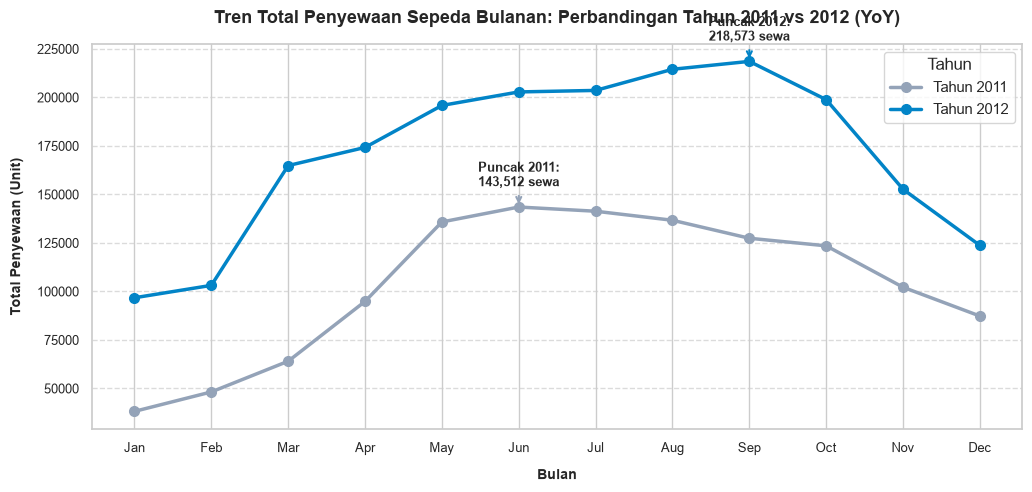

C:\Users\El\AppData\Local\Temp\ipykernel_18812\30108506.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=season_summary, x='season_label', y='avg_rentals', order=season_order, palette=season_colors, ax=ax2)
C:\Users\El\AppData\Local\Temp\ipykernel_18812\30108506.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=weather_summary, x='weather_label', y='avg_rentals', order=weather_order, palette=weather_colors, ax=ax3)


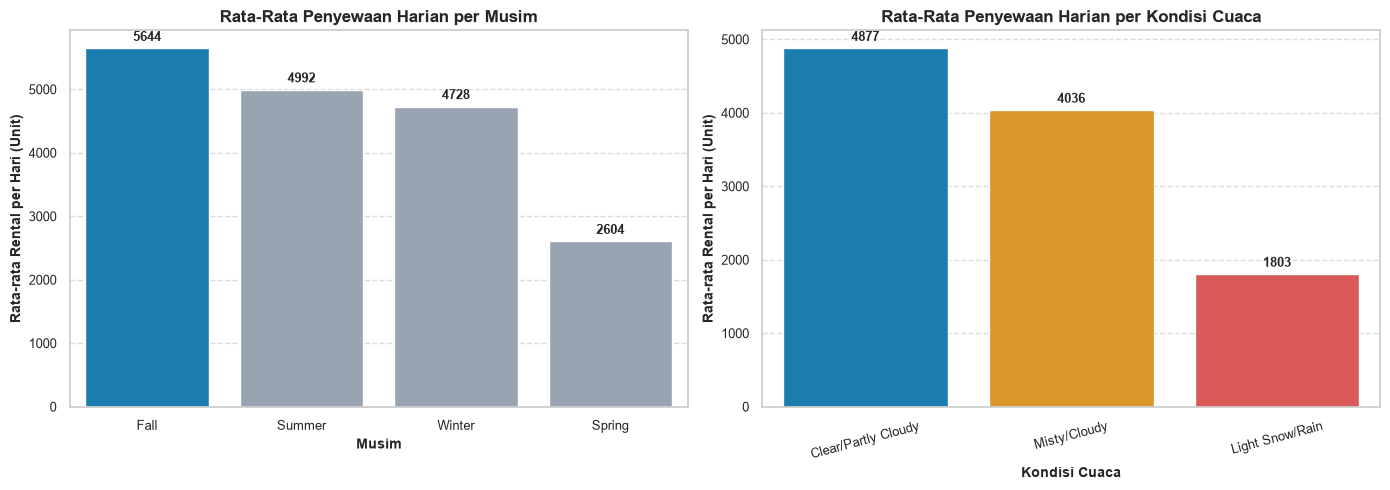

In [16]:
# Visualisasi 1A: Tren Penyewaan Bulanan 2011 vs 2012
fig1, ax1 = plt.subplots(figsize=(12, 5))
monthly_trend = day_df.groupby(['year_label', 'month_label', 'mnth']).agg({'cnt': 'sum'}).reset_index().sort_values(by=['year_label', 'mnth'])

palette_yr = {2011: '#94a3b8', 2012: '#0284c7'}
for yr in [2011, 2012]:
    subset = monthly_trend[monthly_trend['year_label'] == yr]
    ax1.plot(subset['month_label'], subset['cnt'], marker='o', linewidth=2.5, markersize=7, label=f"Tahun {yr}", color=palette_yr[yr])
    max_row = subset.loc[subset['cnt'].idxmax()]
    ax1.annotate(f"Puncak {yr}:\n{max_row['cnt']:,} sewa", 
                 xy=(max_row['month_label'], max_row['cnt']), 
                 xytext=(0, 15), textcoords='offset points',
                 ha='center', fontweight='bold', fontsize=9,
                 arrowprops=dict(arrowstyle='->', color=palette_yr[yr], lw=1.5))

ax1.set_title("Tren Total Penyewaan Sepeda Bulanan: Perbandingan Tahun 2011 vs 2012 (YoY)", fontsize=13, fontweight='bold', pad=15)
ax1.set_xlabel("Bulan", fontweight='bold', labelpad=10)
ax1.set_ylabel("Total Penyewaan (Unit)", fontweight='bold', labelpad=10)
ax1.legend(title="Tahun", frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Visualisasi 1B & 1C: Pengaruh Musim dan Cuaca
fig2, (ax2, ax3) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Musim
season_order = ['Fall', 'Summer', 'Winter', 'Spring']
season_colors = ['#0284c7' if s == 'Fall' else '#94a3b8' for s in season_order]
sns.barplot(data=season_summary, x='season_label', y='avg_rentals', order=season_order, palette=season_colors, ax=ax2)
ax2.set_title("Rata-Rata Penyewaan Harian per Musim", fontweight='bold', fontsize=12)
ax2.set_xlabel("Musim", fontweight='bold')
ax2.set_ylabel("Rata-rata Rental per Hari (Unit)", fontweight='bold')
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold', fontsize=9)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# Plot Cuaca
weather_order = ['Clear/Partly Cloudy', 'Misty/Cloudy', 'Light Snow/Rain']
weather_colors = ['#0284c7' if w == 'Clear/Partly Cloudy' else ('#f59e0b' if w == 'Misty/Cloudy' else '#ef4444') for w in weather_order]
sns.barplot(data=weather_summary, x='weather_label', y='avg_rentals', order=weather_order, palette=weather_colors, ax=ax3)
ax3.set_title("Rata-Rata Penyewaan Harian per Kondisi Cuaca", fontweight='bold', fontsize=12)
ax3.set_xlabel("Kondisi Cuaca", fontweight='bold')
ax3.set_ylabel("Rata-rata Rental per Hari (Unit)", fontweight='bold')
ax3.tick_params(axis='x', rotation=15)
for p in ax3.patches:
    ax3.annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold', fontsize=9)
ax3.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

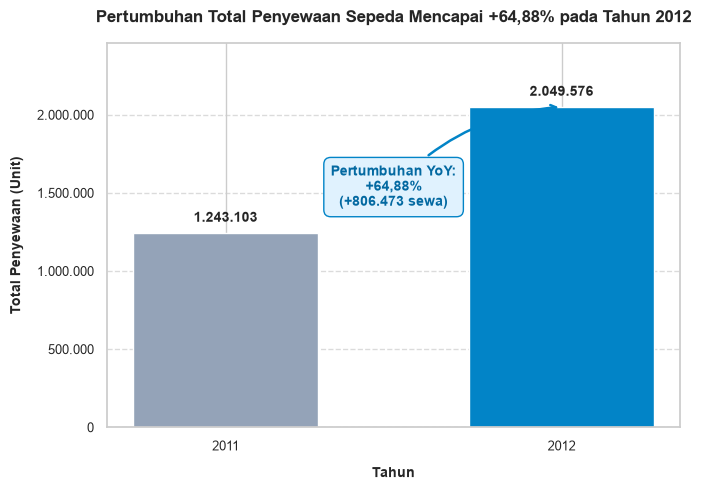

In [17]:
# Visualisasi 1D: Pertumbuhan Total Penyewaan Tahunan (YoY)
fig_yoy, ax_yoy = plt.subplots(figsize=(7, 5))
yearly_rentals = day_df.groupby('year_label')['cnt'].sum().reset_index()

colors_yoy = ['#94a3b8', '#0284c7']
bars = ax_yoy.bar(yearly_rentals['year_label'].astype(str), yearly_rentals['cnt'], color=colors_yoy, width=0.55)

ax_yoy.set_title("Pertumbuhan Total Penyewaan Sepeda Mencapai +64,88% pada Tahun 2012", fontsize=12, fontweight='bold', pad=15)
ax_yoy.set_xlabel("Tahun", fontweight='bold', labelpad=10)
ax_yoy.set_ylabel("Total Penyewaan (Unit)", fontweight='bold', labelpad=10)
ax_yoy.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{int(x):,}".replace(',', '.')))
ax_yoy.grid(axis='y', linestyle='--', alpha=0.7)

# Anotasi angka total pada setiap bar
for bar in bars:
    height = bar.get_height()
    val_str = f"{int(height):,}".replace(',', '.')
    ax_yoy.annotate(val_str,
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 6), textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold', fontsize=10)

# Anotasi panah pertumbuhan YoY
growth_pct = ((yearly_rentals.loc[1, 'cnt'] - yearly_rentals.loc[0, 'cnt']) / yearly_rentals.loc[0, 'cnt']) * 100
growth_str = f"+{growth_pct:.2f}%".replace('.', ',')
diff_val = int(yearly_rentals.loc[1, 'cnt'] - yearly_rentals.loc[0, 'cnt'])
diff_str = f"+{diff_val:,}".replace(',', '.')

ax_yoy.annotate(f"Pertumbuhan YoY:\n{growth_str}\n({diff_str} sewa)",
                xy=(1, yearly_rentals.loc[1, 'cnt']),
                xytext=(0.5, yearly_rentals.loc[1, 'cnt'] * 0.75),
                ha='center', va='center', fontweight='bold', fontsize=10, color='#0369a1',
                arrowprops=dict(arrowstyle="->", color='#0284c7', lw=1.8, connectionstyle="arc3,rad=-0.2"),
                bbox=dict(boxstyle="round,pad=0.5", fc="#e0f2fe", ec="#0284c7", lw=1))

y_max = yearly_rentals['cnt'].max() * 1.2
ax_yoy.set_ylim(0, y_max)
plt.tight_layout()
plt.show()

### Pembahasan & Insight Pertanyaan 1:
1. **Pertumbuhan Masif Tahunan (YoY):** Terjadi peningkatan total penyewaan sebesar **+64,88%**, yaitu dari **1.243.103 sewa** pada tahun 2011 menjadi **2.049.576 sewa** pada tahun 2012 (penambahan 806.473 perjalanan). Rata-rata harian juga meningkat dari 3.406 unit/hari menjadi 5.600 unit/hari.
2. **Pola Tren Bulanan Konsisten:** Kurva tren bulanan pada tahun 2011 dan 2012 memiliki pola kurva lonceng yang selaras, namun volume pada tahun 2012 secara konsisten melampaui 2011 di setiap bulan. Puncak tahun 2011 berada di bulan Juni (143.512 sewa), sedangkan puncak tahun 2012 terjadi di bulan September (218.573 sewa).
3. **Kondisi Musim Optimal:** Musim Gugur (*Fall*) mencatatkan volume tertinggi dengan rata-rata **5.644 unit/hari** (total 1.061.129 sewa), disusul Musim Panas (*Summer*) sebesar **4.992 unit/hari** (total 918.589 sewa). Musim Dingin (*Winter*) mencatatkan rata-rata **4.728 unit/hari**, sedangkan Musim Semi (*Spring*) mencatat rata-rata terendah sebesar **2.604 unit/hari**.
4. **Ketergantungan terhadap Kondisi Cuaca:** Cuaca cerah dan berawan sebagian (*Clear/Partly Cloudy*) menjadi kondisi paling mendukung dengan rata-rata tertinggi (**4.877 unit/hari**). Ketika cuaca berkabut (*Misty/Cloudy*), penyewaan turun menjadi **4.036 unit/hari** (-17,2%). Pada saat hujan ringan atau salju (*Light Snow/Rain*), aktivitas sewa anjlok hingga **1.803 unit/hari** (penurunan 63,0%).

### Pertanyaan 2: Bagaimana perbedaan pola rata-rata penyewaan sepeda antara pengguna kasual (casual) dan pengguna terdaftar (registered) pada hari kerja (workingday) versus hari libur/akhir pekan (weekend/holiday) sepanjang 2011–2012, serta pada rentang jam berapa (hourly peak) lonjakan permintaan terjadi, sebagai dasar perencanaan redistribusi armada antar-stasiun dan promo konversi pengguna kasual?

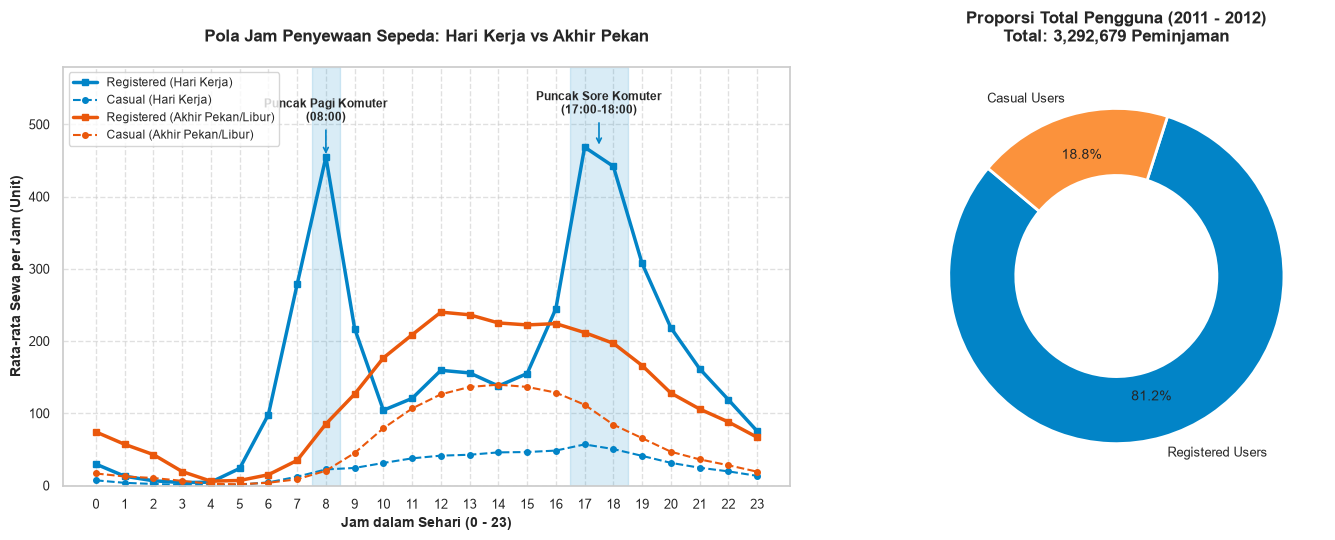

In [18]:
# Visualisasi 2A & 2B: Profil Jam dan Proporsi Pengguna Casual vs Registered
fig3, (ax4, ax5) = plt.subplots(1, 2, figsize=(15, 5.5))

work_df = hour_df[hour_df['workingday_label'] == 'Workingday'].groupby('hr')[['casual', 'registered']].mean().reset_index()
rest_df = hour_df[hour_df['workingday_label'] == 'Weekend/Holiday'].groupby('hr')[['casual', 'registered']].mean().reset_index()

ax4.plot(work_df['hr'], work_df['registered'], color='#0284c7', linewidth=2.5, marker='s', markersize=5, label='Registered (Hari Kerja)')
ax4.plot(work_df['hr'], work_df['casual'], color='#0284c7', linewidth=1.5, linestyle='--', marker='o', markersize=4, label='Casual (Hari Kerja)')
ax4.plot(rest_df['hr'], rest_df['registered'], color='#ea580c', linewidth=2.5, marker='s', markersize=5, label='Registered (Akhir Pekan/Libur)')
ax4.plot(rest_df['hr'], rest_df['casual'], color='#ea580c', linewidth=1.5, linestyle='--', marker='o', markersize=4, label='Casual (Akhir Pekan/Libur)')

ax4.axvspan(7.5, 8.5, color='#0284c7', alpha=0.15)
ax4.axvspan(16.5, 18.5, color='#0284c7', alpha=0.15)

# Atur batas sumbu Y dan posisi anotasi agar tidak menabrak judul
ax4.set_ylim(0, 580)
ax4.annotate("Puncak Pagi Komuter\n(08:00)", xy=(8, 455), xytext=(8, 505),
             ha='center', fontweight='bold', fontsize=8.5, arrowprops=dict(arrowstyle='->', lw=1.2, color='#0284c7'))
ax4.annotate("Puncak Sore Komuter\n(17:00-18:00)", xy=(17.5, 468), xytext=(17.5, 515),
             ha='center', fontweight='bold', fontsize=8.5, arrowprops=dict(arrowstyle='->', lw=1.2, color='#0284c7'))

ax4.set_title("Pola Jam Penyewaan Sepeda: Hari Kerja vs Akhir Pekan", fontweight='bold', fontsize=12, pad=18)
ax4.set_xlabel("Jam dalam Sehari (0 - 23)", fontweight='bold')
ax4.set_ylabel("Rata-rata Sewa per Jam (Unit)", fontweight='bold')
ax4.set_xticks(range(0, 24))
ax4.legend(frameon=True, fontsize=8.5, loc='upper left')
ax4.grid(True, linestyle='--', alpha=0.6)

total_c = day_df['casual'].sum()
total_r = day_df['registered'].sum()
ax5.pie(
    [total_r, total_c],
    labels=['Registered Users', 'Casual Users'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#0284c7', '#fb923c'],
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
ax5.set_title(f"Proporsi Total Pengguna (2011 - 2012)\nTotal: {total_r + total_c:,} Peminjaman", fontweight='bold', fontsize=12, pad=18)

plt.tight_layout()
plt.show()

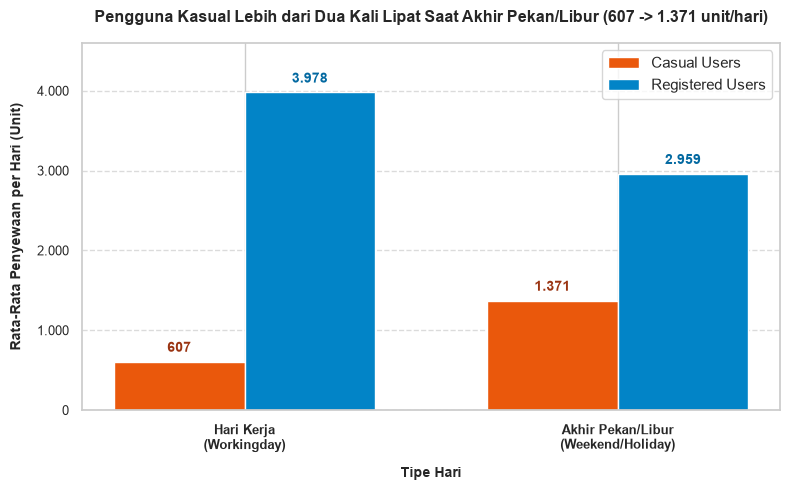

In [19]:
# Visualisasi 2C: Rata-Rata Penyewaan Harian Casual vs Registered (Hari Kerja vs Akhir Pekan/Libur)
fig_2c, ax_2c = plt.subplots(figsize=(8, 5))

avg_daily = day_df.groupby('workingday_label')[['casual', 'registered']].mean().reindex(['Workingday', 'Weekend/Holiday'])

labels = ['Hari Kerja\n(Workingday)', 'Akhir Pekan/Libur\n(Weekend/Holiday)']
x = np.arange(len(labels))
width = 0.35

rects1 = ax_2c.bar(x - width/2, avg_daily['casual'], width, label='Casual Users', color='#ea580c')
rects2 = ax_2c.bar(x + width/2, avg_daily['registered'], width, label='Registered Users', color='#0284c7')

ax_2c.set_title("Pengguna Kasual Lebih dari Dua Kali Lipat Saat Akhir Pekan/Libur (607 -> 1.371 unit/hari)",
                fontsize=11.5, fontweight='bold', pad=15)
ax_2c.set_xlabel("Tipe Hari", fontweight='bold', labelpad=10)
ax_2c.set_ylabel("Rata-Rata Penyewaan per Hari (Unit)", fontweight='bold', labelpad=10)
ax_2c.set_xticks(x)
ax_2c.set_xticklabels(labels, fontweight='bold')
ax_2c.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{int(v):,}".replace(',', '.')))
ax_2c.grid(axis='y', linestyle='--', alpha=0.7)
ax_2c.legend(frameon=True, loc='upper right')
ax_2c.set_ylim(0, 4600)

for rect in rects1:
    h = rect.get_height()
    val_str = f"{int(round(h)):,}".replace(',', '.')
    ax_2c.annotate(val_str,
                   xy=(rect.get_x() + rect.get_width() / 2, h),
                   xytext=(0, 5), textcoords="offset points",
                   ha='center', va='bottom', fontweight='bold', fontsize=10, color='#9a3412')

for rect in rects2:
    h = rect.get_height()
    val_str = f"{int(round(h)):,}".replace(',', '.')
    ax_2c.annotate(val_str,
                   xy=(rect.get_x() + rect.get_width() / 2, h),
                   xytext=(0, 5), textcoords="offset points",
                   ha='center', va='bottom', fontweight='bold', fontsize=10, color='#0369a1')

plt.tight_layout()
plt.show()

### Pembahasan & Insight Pertanyaan 2:
1. **Perbandingan Rata-Rata Harian (Hari Kerja vs Akhir Pekan):** Berdasarkan grafik rata-rata harian di atas, pola mobilitas pengguna terbagi dengan sangat tegas:
   - **Hari Kerja (500 hari):** Didominasi oleh pengguna terdaftar dengan rata-rata **3.978 unit/hari** (porsi **86,77%** dari total sewa hari kerja), sedangkan pengguna kasual hanya mencatat rata-rata **607 unit/hari** (porsi **13,23%**). Rata-rata total sewa mencapai **4.585 unit/hari**.
   - **Akhir Pekan/Hari Libur (231 hari):** Rata-rata sewa pengguna kasual meningkat lebih dari dua kali lipat menjadi **1.371 unit/hari** (porsi **31,66%** dari total sewa libur), sedangkan pengguna terdaftar mencatat rata-rata **2.959 unit/hari** (porsi **68,34%**). Rata-rata total sewa harian sebesar **4.330 unit/hari**.
2. **Pola Bimodal Komuter pada Hari Kerja:** Pengguna terdaftar menunjukkan perilaku mobilitas komuter harian yang sangat kental dengan dua jam puncak (*bimodal peak*):
   - **Puncak Pagi:** Pukul **08:00** (rata-rata 455 unit/jam terdaftar), mencerminkan perjalanan berangkat kerja/kampus.
   - **Puncak Sore:** Pukul **17:00–18:00** (rata-rata 442–468 unit/jam terdaftar), mencerminkan arus balik pulang kantor.
3. **Pola Unimodal Rekreasi pada Akhir Pekan/Libur:** Sebaliknya, pada akhir pekan dan hari libur, pengguna kasual menunjukkan pola rekreasi kurva tunggal (*unimodal*). Aktivitas mulai meningkat sejak pagi dan mencapai lonjakan permintaan tertinggi pada rentang pukul **12:00 hingga 16:00** (rata-rata 126–140 unit/jam, dengan puncak pada pukul 14:00 sebesar 140 unit/jam).
4. **Proporsi Keseluruhan (2 Tahun):** Secara agregat, pengguna terdaftar mencakup **81,2%** (2.672.662 perjalanan), sedangkan pengguna kasual menyumbang **18,8%** (620.017 perjalanan).

## Analisis Lanjutan (Opsional)

Sebagai bagian dari analisis mendalam, diterapkan teknik analisis lanjutan berupa **Clustering (Manual Grouping)** dan **Binning** untuk menjawab Pertanyaan 3:
- **Manual Grouping (Part of Day):** Mengelompokkan 24 jam menjadi 5 segmen operasional harian:
  1. *Dini Hari (00:00 - 05:59)*: Masa perbaikan & pengisian ulang armada.
  2. *Pagi Sibuk (06:00 - 09:59)*: Jam masuk kerja/sekolah komuter.
  3. *Jam Kerja/Siang (10:00 - 15:59)*: Jam aktivitas harian normal & mobilitas bisnis lokal.
  4. *Sore Sibuk (16:00 - 19:59)*: Jam pulang kantor komuter.
  5. *Malam (20:00 - 23:59)*: Jam rekreasi malam & kepulangan santai.
- **Binning Suhu Lingkungan (Temperature Tiers):** Mengelompokkan suhu fisik riil ke dalam 4 kategori kenyamanan termal:
  - Dingin (<10°C), Sejuk (10–20°C), Hangat/Ideal (20–28°C), dan Panas (>28°C).
- **Binning Kelembapan Udara (Humidity Tiers):**
  - Kering (<45%), Ideal (45–70%), dan Lembap/Basah (>70%).

In [20]:
# Penerapan Manual Grouping (Part of Day) dan Binning (Suhu & Kelembapan)
def assign_part_of_day(hr):
    if 0 <= hr < 6:
        return '1. Dini Hari (00-06)'
    elif 6 <= hr < 10:
        return '2. Pagi Sibuk (06-10)'
    elif 10 <= hr < 16:
        return '3. Jam Kerja/Siang (10-16)'
    elif 16 <= hr < 20:
        return '4. Sore Sibuk (16-20)'
    else:
        return '5. Malam (20-24)'

hour_df['part_of_day'] = hour_df['hr'].apply(assign_part_of_day)

day_df['temp_bin'] = pd.cut(
    day_df['actual_temp'], 
    bins=[-np.inf, 10, 20, 28, np.inf], 
    labels=['Dingin (<10°C)', 'Sejuk (10-20°C)', 'Hangat/Ideal (20-28°C)', 'Panas (>28°C)']
)

day_df['hum_bin'] = pd.cut(
    day_df['actual_hum'], 
    bins=[-np.inf, 45, 70, np.inf], 
    labels=['Kering (<45%)', 'Ideal (45-70%)', 'Lembap/Basah (>70%)']
)

pod_summary = hour_df.groupby('part_of_day').agg(
    avg_rentals_per_hour=('cnt', 'mean'),
    total_rentals=('cnt', 'sum'),
    total_hours=('cnt', 'count')
).reset_index()

pod_summary

,part_of_day,avg_rentals_per_hour,total_rentals,total_hours
0,1. Dini Hari (00-06),24.908559,106509,4276
1,2. Pagi Sibuk (06-10),216.704061,629742,2906
2,3. Jam Kerja/Siang (10-16),230.192493,1005711,4369
3,4. Sore Sibuk (16-20),377.629973,1101169,2916
4,5. Malam (20-24),154.377747,449548,2912


C:\Users\El\AppData\Local\Temp\ipykernel_18812\141383661.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pod_summary, x='part_of_day', y='avg_rentals_per_hour', palette=palette_pod, ax=ax6)


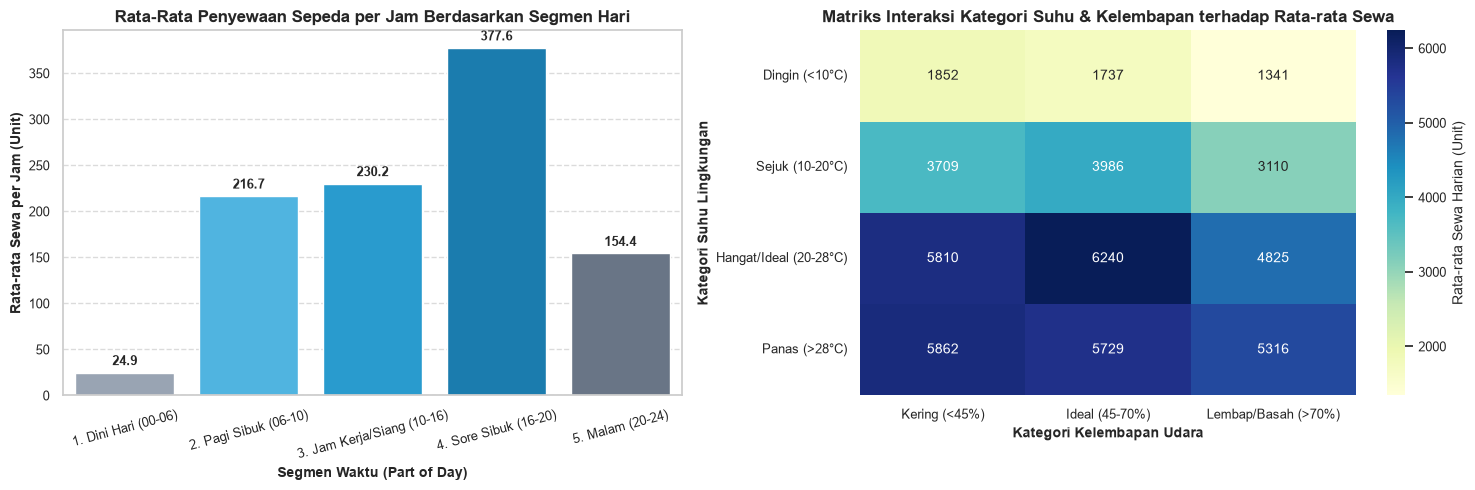

In [21]:
# Visualisasi 3A & 3B: Segmentasi Waktu (Part of Day) & Matriks Interaksi Suhu-Kelembapan
fig4, (ax6, ax7) = plt.subplots(1, 2, figsize=(15, 5))

palette_pod = ['#94a3b8', '#38bdf8', '#0ea5e9', '#0284c7', '#64748b']
sns.barplot(data=pod_summary, x='part_of_day', y='avg_rentals_per_hour', palette=palette_pod, ax=ax6)
ax6.set_title("Rata-Rata Penyewaan Sepeda per Jam Berdasarkan Segmen Hari", fontweight='bold', fontsize=12)
ax6.set_xlabel("Segmen Waktu (Part of Day)", fontweight='bold')
ax6.set_ylabel("Rata-rata Sewa per Jam (Unit)", fontweight='bold')
ax6.tick_params(axis='x', rotation=15)
for p in ax6.patches:
    ax6.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold', fontsize=9)
ax6.grid(axis='y', linestyle='--', alpha=0.7)

pivot_temp_hum = day_df.pivot_table(index='temp_bin', columns='hum_bin', values='cnt', aggfunc='mean')
sns.heatmap(pivot_temp_hum, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Rata-rata Sewa Harian (Unit)'}, ax=ax7)
ax7.set_title("Matriks Interaksi Kategori Suhu & Kelembapan terhadap Rata-rata Sewa", fontweight='bold', fontsize=12)
ax7.set_xlabel("Kategori Kelembapan Udara", fontweight='bold')
ax7.set_ylabel("Kategori Suhu Lingkungan", fontweight='bold')

plt.tight_layout()
plt.show()

### Pembahasan & Insight Analisis Lanjutan:
1. **Prioritas Operasional Segmen Hari:**
   - Segmen **Sore Sibuk (16:00 - 20:00)** merupakan jendela waktu paling kritis dengan rata-rata **377,6 unit/jam** dan total volume mencapai **1.101.169 penyewaan** (33,4% dari seluruh sewa sepanjang 2 tahun).
   - Segmen **Jam Kerja/Siang (10:00 - 16:00)** menduduki posisi kedua dengan rata-rata **230,2 unit/jam** (total 1.005.711 sewa), disusul **Pagi Sibuk (06:00 - 10:00)** dengan rata-rata **216,7 unit/jam**.
   - Segmen **Dini Hari (00:00 - 06:00)** sangat sepi (rata-rata **24,9 unit/jam**), yang menjadikannya *golden window* ideal bagi tim logistik untuk melakukan pembersihan dock, redistribusi unit secara masif, dan inspeksi mekanik tanpa mengganggu pelanggan.
2. **Kondisi Sweet Spot Lingkungan:**
   - Dari matriks interaksi suhu-kelembapan, kondisi optimal dengan permintaan tertinggi berada pada kombinasi **Suhu Hangat/Ideal (20–28°C) dan Kelembapan Kering hingga Ideal**, dengan rata-rata sewa menembus **5.800–6.240 unit per hari**.
   - Sebaliknya, pada kondisi **Suhu Dingin (<10°C) dipadu Kelembapan Lembap/Basah (>70%)**, rata-rata sewa anjlok drastis hingga **<1.400 unit per hari** (rata-rata 1.341 unit/hari, berdasarkan 13 hari data).

## Conclusion

### 1. Kesimpulan Pertanyaan 1 (Tren Waktu, Musim & Cuaca)
- **Tren Pertumbuhan Tahunan:** Terjadi peningkatan adopsi sistem penyewaan sepeda sebesar **+64,88%** dari tahun 2011 (1.243.103 perjalanan) ke tahun 2012 (2.049.576 perjalanan), dengan rata-rata harian naik dari 3.406 menjadi 5.600 unit/hari. Kurva bulanan selalu menunjukkan volume 2012 lebih tinggi di semua bulan dibanding 2011.
- **Pengaruh Musim:** Volume peminjaman mencapai angka tertinggi pada **Musim Gugur (Fall)** dengan rata-rata **5.644 unit/hari** (total 1.061.129 sewa), diikuti oleh **Musim Panas (Summer)** dengan rata-rata **4.992 unit/hari** (total 918.589 sewa). Musim Semi (Spring) mencatatkan rata-rata terendah sebesar 2.604 unit/hari.
- **Pengaruh Cuaca:** Cuaca cerah/berawan sebagian (*Clear/Partly Cloudy*) mendominasi permintaan dengan rata-rata **4.877 unit/hari**, sedangkan cuaca hujan ringan/salju (*Light Snow/Rain*) menekan permintaan hingga tersisa **1.803 unit/hari** (turun 63,0%).
- **Implikasi Tindakan:** Temuan ini menjadi dasar bagi manajemen untuk menyiagakan kapasitas armada penuh pada bulan Mei hingga Oktober (musim panas & gugur), serta menjadwalkan perbaikan besar dan peremajaan unit di periode sepi (musim dingin dan awal musim semi).

### 2. Kesimpulan Pertanyaan 2 (Pola Pengguna Casual vs Registered)
- **Perbedaan Pola Rata-Rata Harian:**
  - **Hari Kerja (500 hari):** Didominasi secara masif oleh pengguna terdaftar (*registered*) dengan rata-rata **3.978 unit/hari** (**86,77%** dari total sewa hari kerja), sedangkan pengguna kasual hanya mencatatkan rata-rata **607 unit/hari** (**13,23%**). Rata-rata total sewa hari kerja adalah 4.585 unit/hari.
  - **Akhir Pekan/Hari Libur (231 hari):** Rata-rata peminjaman pengguna kasual (*casual*) melonjak lebih dari dua kali lipat menjadi **1.371 unit/hari** (**31,66%** dari total sewa libur), sedangkan pengguna terdaftar mencatat rata-rata **2.959 unit/hari** (**68,34%**). Rata-rata total sewa akhir pekan adalah 4.330 unit/hari.
- **Rentang Jam Sibuk (Hourly Peak):**
  - Pada hari kerja, terjadi pola *bimodal* komuter dengan dua lonjakan tajam pada jam berangkat kantor (**08:00**, rata-rata 455 unit/jam terdaftar) dan jam pulang kantor (**17:00–18:00**, rata-rata 442–468 unit/jam terdaftar).
  - Pada akhir pekan/hari libur, terjadi pola *unimodal* rekreasi dengan aktivitas pengguna kasual terkonsentrasi di siang hingga sore hari pada rentang pukul **12:00 hingga 16:00** (rata-rata 126–140 unit/jam, dengan puncak pada pukul 14:00 sebesar 140 unit/jam).
- **Implikasi Tindakan:** Menjadi dasar perencanaan redistribusi armada harian (rebalancing ke area perumahan sebelum pukul 07:00 dan ke area perkantoran sebelum pukul 16:00) serta target kampanye konversi pengguna kasual di akhir pekan.

### 3. Kesimpulan Pertanyaan 3 (Analisis Lanjutan: Segmentasi Waktu & Suhu)
- **Segmentasi Waktu (Part of Day):** Segmen **Sore Sibuk (16:00–20:00)** merupakan kontributor terbesar dengan rata-rata **377,6 unit/jam** (total 1.101.169 sewa, menyumbang 33,4% dari seluruh perjalanan), diikuti **Jam Kerja/Siang (10:00–16:00)** sebesar **230,2 unit/jam** dan **Pagi Sibuk (06:00–10:00)** sebesar **216,7 unit/jam**.
- **Jendela Perawatan (Dini Hari):** Segmen **Dini Hari (00:00–06:00)** memiliki volume sangat rendah dengan rata-rata **24,9 unit/jam** (hanya 3,2% volume). Waktu ini menjadi dasar penjadwalan ideal bagi tim operasional untuk melakukan logistik penataan ulang stasiun, inspeksi keselamatan, dan perawatan teknis tanpa mengganggu pengguna.
- **Kondisi Termal:** Rentang suhu **20–28°C (Hangat/Ideal)** dengan kelembapan di bawah 70% menghasilkan volume sewa tertinggi (**5.800–6.240 unit/hari**), sedangkan suhu dingin (<10°C) disertai kelembapan tinggi menekan penyewaan hingga di bawah **1.400 unit/hari** (rata-rata 1.341 unit/hari, berdasarkan 13 hari data).

---

### Rekomendasi Aksi:

1. **Penjadwalan Redistribusi Armada (*Dynamic Rebalancing*) Berbasis Jam Sibuk:**
   - **Hari Kerja:** Pindahkan ketersediaan unit ke stasiun penyangga/perumahan sebelum pukul 07:00 pagi untuk melayani komuter pagi, lalu alihkan kembali armada ke kawasan perkantoran komersial sebelum pukul 16:00 sore untuk menyambut arus kepulangan kerja.
   - **Akhir Pekan:** Prioritaskan alokasi unit ke stasiun sekitar ruang terbuka hijau, taman rekreasi, dan jalur wisata mulai pukul 10:00 hingga 16:00, karena rata-rata pengguna kasual akhir pekan/libur mencapai 1.371 unit/hari (lebih dari 2x hari kerja) dan memuncak pukul 12:00–16:00.
2. **Program Konversi Pengguna Kasual Menjadi Anggota Terdaftar:**
   - Mengingat terdapat **316.732 peminjaman kasual pada akhir pekan dan hari libur** (rata-rata **1.371 unit per hari**), tawarkan promo keanggotaan terdaftar (*commuter membership trial*) melalui aplikasi pada saat pengguna kasual menyelesaikan perjalanan rekreasinya di akhir pekan.
3. **Penjadwalan Perawatan Armada (*Fleet Maintenance*) di Musim Sepi & Dini Hari:**
   - Jadwalkan perbaikan besar, peremajaan suku cadang, dan pemeliharaan dermaga stasiun secara intensif pada musim sepi (musim dingin Desember–Februari dan musim semi), serta manfaatkan jendela waktu dini hari (00:00–06:00) untuk servis harian agar kesiapan armada maksimal saat musim puncak (musim gugur dengan rata-rata 5.644 unit/hari & musim panas 4.992 unit/hari).
4. **Sistem Notifikasi dan Penyesuaian Operasional Berdasarkan Prakiraan Cuaca:**
   - Manfaatkan prakiraan cuaca real-time untuk mengirimkan notifikasi keselamatan saat hujan atau salju diprediksi turun, serta alokasikan insentif tarif atau diskon khusus di hari-hari sejuk berawan guna menjaga volume peminjaman sepeda.